In [1]:
# Checked (final)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from metricsCalculation import DataPreparationUtils as utils

In [3]:
listOf1ServerLogFolders = {
    '../data/1_server/5_clients': 5,
    '../data/1_server/10_clients': 10,
    '../data/1_server/15_clients': 15,
    '../data/1_server/20_clients': 20,
    '../data/1_server/25_clients': 25,
    '../data/1_server/30_clients': 30,
}

listOf3ServerLogFolders = {
    '../data/3_server/5_clients': 5,
    '../data/3_server/10_clients': 10,
    '../data/3_server/15_clients': 15,
    '../data/3_server/20_clients': 20,
    '../data/3_server/25_clients': 25,
    '../data/3_server/30_clients': 30,
}

listOf5ServerLogFolders = {
    '../data/5_server/5_clients': 5,
    '../data/5_server/10_clients': 10,
    '../data/5_server/15_clients': 15,
    '../data/5_server/20_clients': 20,
    '../data/5_server/25_clients': 25,
    '../data/5_server/30_clients': 30,
}

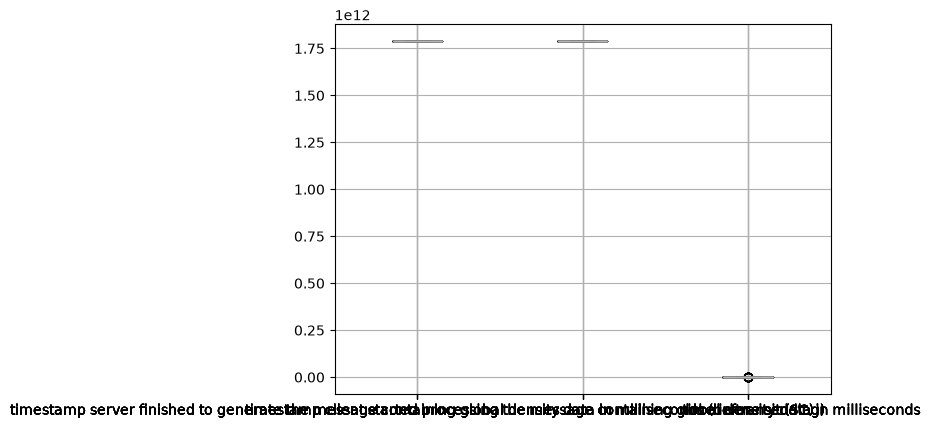

In [8]:
dfSC1Server = pd.DataFrame(columns=['Number of Mobile Sensing Clients', 'SC (Median)'])

for (logFolder, clientNumber) in listOf1ServerLogFolders.items():
    dfClientProcessedLog = utils.readInClientLogsForScenario(logFolder)[1]
    dfServerProducerLog = utils.readInServerLogsForScenario(logFolder)[0]

    dfWithScMetric = utils.generateMetricSC(dfServerProducerLog, dfClientProcessedLog)
    dfWithScMetric.boxplot()

    dfWithScMetricDescribe = dfWithScMetric.describe()
    median = dfWithScMetricDescribe.iat[5,2]

    dfSC1Server.loc[len(dfSC1Server)] = [clientNumber, median]


dfSC3Server = pd.DataFrame(columns=['Number of Mobile Sensing Clients', 'SC (Median)'])

for (logFolder, clientNumber) in listOf3ServerLogFolders.items():
    dfClientProcessedLog = utils.readInClientLogsForScenario(logFolder)[1]
    dfServerProducerLog = utils.readInServerLogsForScenario(logFolder)[0]

    dfWithScMetric = utils.generateMetricSC(dfServerProducerLog, dfClientProcessedLog)

    dfWithScMetricDescribe = dfWithScMetric.describe()
    median = dfWithScMetricDescribe.iat[5,2]

    dfSC3Server.loc[len(dfSC3Server)] = [clientNumber, median]

dfSC5Server = pd.DataFrame(columns=['Number of Mobile Sensing Clients', 'SC (Median)'])

for (logFolder, clientNumber) in listOf5ServerLogFolders.items():
    dfClientProcessedLog = utils.readInClientLogsForScenario(logFolder)[1]
    dfServerProducerLog = utils.readInServerLogsForScenario(logFolder)[0]

    dfWithScMetric = utils.generateMetricSC(dfServerProducerLog, dfClientProcessedLog)

    dfWithScMetricDescribe = dfWithScMetric.describe()
    median = dfWithScMetricDescribe.iat[5,2]

    dfSC5Server.loc[len(dfSC5Server)] = [clientNumber, median]

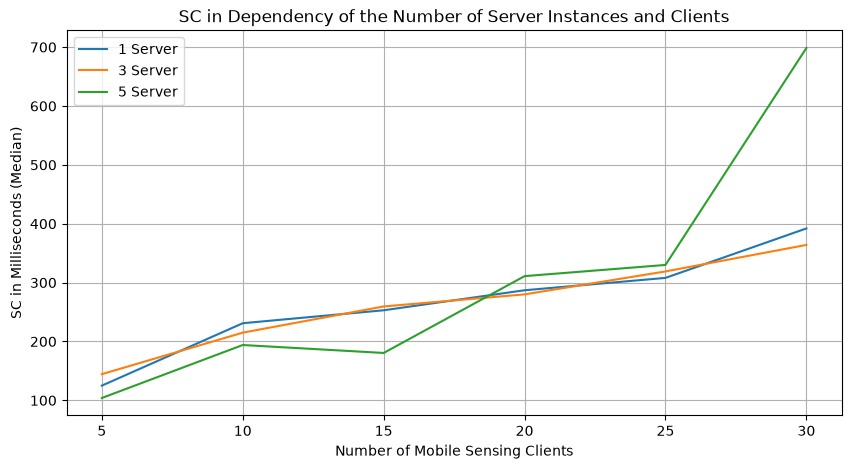

In [5]:
figure = plt.figure()

plt.plot(dfSC1Server['Number of Mobile Sensing Clients'], dfSC1Server['SC (Median)'], label='1 Server')
plt.plot(dfSC3Server['Number of Mobile Sensing Clients'], dfSC3Server['SC (Median)'], label='3 Server')
plt.plot(dfSC5Server['Number of Mobile Sensing Clients'], dfSC5Server['SC (Median)'], label='5 Server')

plt.title("SC in Dependency of the Number of Server Instances and Clients")
plt.xlabel("Number of Mobile Sensing Clients")
plt.ylabel("SC in Milliseconds (Median)")

plt.grid()
plt.legend()

figure.set_figwidth(10)
figure.set_figheight(5)

plt.show()

<Axes: >

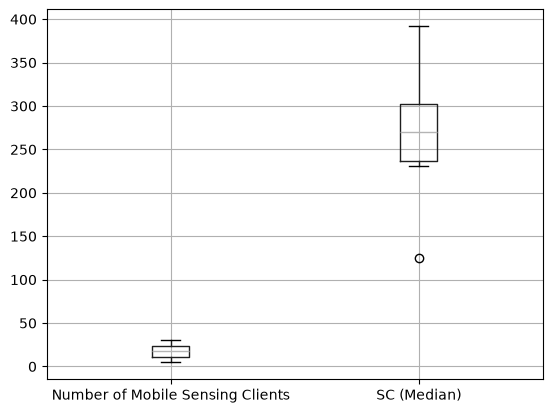

In [6]:
dfSC1Server.boxplot()